In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/analytics/fato_pedidos.csv"
)

print("Quantidade de registros:", len(df))
display(df.head())

Quantidade de registros: 98666


,order_id,items_count,order_price_cents,order_freight_cents,order_price,order_freight,customer_id,customer_unique_id,customer_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_month,order_year,is_delivered,is_in_analysis_period,is_eligible_analysis,ticket_sem_frete
0,00010242fe8c5a6d1ba2dd792cb16214,1,5890,1329,58.90,13.29,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,RJ,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,2017-09,2017,True,True,True,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,23990,1993,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,2017-04,2017,True,True,True,239.90
2,000229ec398224ef6ca0657da4fc703e,1,19900,1787,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,MG,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,2018-01,2018,True,True,True,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,1299,1279,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,SP,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,2018-08,2018,True,False,False,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,19990,1814,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,2017-02,2017,True,True,True,199.90


In [2]:
# Converter as colunas de datas
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"]
)

df["order_delivered_customer_date"] = pd.to_datetime(
    df["order_delivered_customer_date"]
)

df["order_estimated_delivery_date"] = pd.to_datetime(
    df["order_estimated_delivery_date"]
)

# Filtrar pedidos elegíveis do projeto
pedidos = df[
    (df["is_eligible_analysis"] == True)
    & df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna()
].copy()

# Calcular o atraso em dias corridos
pedidos["dias_atraso"] = (
    pedidos["order_delivered_customer_date"].dt.normalize()
    - pedidos["order_estimated_delivery_date"].dt.normalize()
).dt.days.clip(lower=0)

# Identificar pedidos atrasados
pedidos["atrasou"] = pedidos["dias_atraso"] > 0

# Agrupar os resultados por estado
atrasos_estado = (
    pedidos.groupby("customer_state")
    .agg(
        total_pedidos=("order_id", "nunique"),
        pedidos_atrasados=("atrasou", "sum"),
        dias_atraso_medio=("dias_atraso", "mean")
    )
    .reset_index()
)

# Calcular percentual de atrasos
atrasos_estado["percentual_atraso"] = (
    atrasos_estado["pedidos_atrasados"]
    / atrasos_estado["total_pedidos"] * 100
).round(2)

# Ordenar pelos estados com mais pedidos atrasados
atrasos_estado = atrasos_estado.sort_values(
    "pedidos_atrasados",
    ascending=False
)

display(atrasos_estado.head(10))

,customer_state,total_pedidos,pedidos_atrasados,dias_atraso_medio,percentual_atraso
25,SP,37235,1532,0.375883,4.11
18,RJ,11587,1453,1.723570,12.54
10,MG,10619,507,0.406347,4.77
4,BA,3094,395,1.534583,12.77
22,RS,5034,316,0.649583,6.28
23,SC,3336,285,0.718825,8.54
7,ES,1889,214,1.280042,11.33
17,PR,4576,189,0.350306,4.13
5,CE,1218,176,2.193760,14.45
15,PE,1504,149,1.182181,9.91


### Análise 1 — Atrasos nas entregas por estado

**Objetivo:** Identificar quais estados apresentam maior quantidade e percentual de pedidos entregues após o prazo previsto.

**Resultados preliminares:**

- São Paulo registrou 1.532 pedidos atrasados, representando 4,11% dos pedidos analisados no estado.
- Rio de Janeiro apresentou 1.453 pedidos atrasados, com uma taxa de 12,54%.
- Bahia apresentou 395 pedidos atrasados, correspondendo a 12,77%.
- Ceará apresentou uma taxa de atraso de 14,45%, a maior entre os dez estados com mais pedidos atrasados.

**Interpretação:**

Embora São Paulo lidere em quantidade absoluta de atrasos, o Rio de Janeiro apresenta uma incidência proporcionalmente maior. Isso demonstra a importância de comparar tanto o volume quanto a taxa de atrasos.

**Próxima etapa:** Cruzar os pedidos atrasados com as avaliações e comentários dos consumidores para identificar reclamações relacionadas à demora na entrega.

In [3]:
import pandas as pd

# Carregar as avaliações dos clientes
avaliacoes = pd.read_csv(
    "../data/raw/olist_order_reviews_dataset.csv"
)

# Verificar quantidade de avaliações
print("Quantidade de avaliações:", len(avaliacoes))

# Verificar as colunas disponíveis
print("\nColunas:")
print(avaliacoes.columns.tolist())

# Visualizar os primeiros registros
display(avaliacoes.head())

Quantidade de avaliações: 99224

Colunas:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [4]:
import re
import unicodedata

# Unir título e mensagem das avaliações
avaliacoes["comentario_completo"] = (
    avaliacoes["review_comment_title"].fillna("")
    + " "
    + avaliacoes["review_comment_message"].fillna("")
)

# Padronizar textos para facilitar a busca
def normalizar_texto(texto):
    texto = str(texto).lower()

    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    return texto

avaliacoes["comentario_normalizado"] = (
    avaliacoes["comentario_completo"].apply(normalizar_texto)
)

# Expressões associadas a reclamações de demora
padrao_atraso = (
    r"\batrasad[oa]s?\b|"
    r"\batrasou\b|"
    r"\bdemorou\b|"
    r"\bdemora\b|"
    r"\bdemorando\b|"
    r"\bnao chegou\b|"
    r"\bainda nao recebi\b|"
    r"\bnao recebi\b|"
    r"\bfora do prazo\b|"
    r"\bprazo de entrega\b"
)

# Identificar comentários potencialmente relacionados a atrasos
avaliacoes["menciona_atraso"] = (
    avaliacoes["comentario_normalizado"]
    .str.contains(padrao_atraso, regex=True, na=False)
)

# Selecionar avaliações negativas que mencionam demora
reclamacoes = avaliacoes[
    (avaliacoes["review_score"] <= 2)
    & (avaliacoes["menciona_atraso"])
].copy()

print("Avaliações identificadas:", len(reclamacoes))

display(
    reclamacoes[
        ["review_score", "review_comment_message"]
    ].head(15)
)

Avaliações identificadas: 2939


,review_score,review_comment_message
19,1,Péssimo
32,1,Sempre compro pela Internet e a entrega ocorre...
68,1,O produto não chegou no prazo estipulado e cau...
128,2,Demorou de mais pra entrega
149,1,EU NÃO RECEBI O PRODUTO E CONSTA NO SISTEMA QU...
168,1,Comprei o produto dia 25 de fevereiro e hoje d...
169,1,fiz minha compra faz 30 dias e não recebi aind...
197,1,aqui está descrevendo como entregue só que ate...
239,1,"Demora na entrega, detestei o atendimento e NU..."
241,1,o meu produto não chegou... segundo o rastreio...


In [5]:
# Relacionar as reclamações aos pedidos analisados
reclamacoes_estado = reclamacoes.merge(
    pedidos[[
        "order_id",
        "customer_state",
        "atrasou",
        "dias_atraso"
    ]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Evitar contar mais de uma avaliação do mesmo pedido
reclamacoes_estado = reclamacoes_estado.drop_duplicates(
    subset=["order_id"]
)

# Contar pedidos com possíveis reclamações por estado
ranking_reclamacoes = (
    reclamacoes_estado
    .groupby("customer_state")
    .agg(
        pedidos_com_reclamacao=("order_id", "nunique"),
        reclamacoes_com_atraso_real=("atrasou", "sum")
    )
    .reset_index()
)

# Adicionar o total de pedidos de cada estado
ranking_reclamacoes = ranking_reclamacoes.merge(
    atrasos_estado[[
        "customer_state",
        "total_pedidos"
    ]],
    on="customer_state",
    how="left"
)

# Calcular a taxa de possíveis reclamações
ranking_reclamacoes["taxa_reclamacao"] = (
    ranking_reclamacoes["pedidos_com_reclamacao"]
    / ranking_reclamacoes["total_pedidos"] * 100
).round(2)

# Ordenar por quantidade de reclamações
ranking_reclamacoes = ranking_reclamacoes.sort_values(
    "pedidos_com_reclamacao",
    ascending=False
)

display(ranking_reclamacoes.head(15))


,customer_state,pedidos_com_reclamacao,reclamacoes_com_atraso_real,total_pedidos,taxa_reclamacao
25,SP,603,274,37235,1.62
18,RJ,512,365,11587,4.42
10,MG,210,101,10619,1.98
4,BA,119,86,3094,3.85
22,RS,104,66,5034,2.07
23,SC,100,64,3336,3.00
17,PR,72,31,4576,1.57
5,CE,62,50,1218,5.09
7,ES,62,41,1889,3.28
15,PE,54,42,1504,3.59


### Análise de reclamações relacionadas à demora na entrega

**Objetivo:** Identificar os estados brasileiros com maior quantidade e proporção de pedidos associados a avaliações negativas que mencionam demora ou problemas de entrega.

**Metodologia:** Foram selecionadas avaliações com notas de 1 a 2 e expressões associadas a atraso. Os registros foram relacionados aos pedidos entregues e elegíveis do recorte analisado, considerando cada pedido apenas uma vez.

**Resultados preliminares:**

- São Paulo apresentou o maior volume de possíveis reclamações: 603 pedidos, correspondendo a 1,62%.
- Rio de Janeiro apresentou 512 possíveis reclamações (4,42%), das quais 365 estavam associadas a entregas efetivamente atrasadas.
- Minas Gerais registrou 210 possíveis reclamações (1,98%).
- Alagoas apresentou uma taxa de 6,58%, a maior entre os 15 estados exibidos.

**Interpretação:** Os resultados indicam que volume absoluto e incidência proporcional de reclamações devem ser analisados separadamente. Estados com maior quantidade de pedidos tendem a apresentar mais ocorrências, enquanto a taxa permite comparar estados com diferentes volumes.

**Limitações:** A identificação por palavras-chave é preliminar e não equivale a uma classificação validada das reclamações. A análise também exclui pedidos não entregues e avaliações sem comentários identificáveis.

Resposta da pergunta: - Quais estados reclamam mais sobre a demora no frete?

Na análise exploratória das avaliações negativas relacionadas à demora na entrega, São Paulo apresentou o maior volume de possíveis reclamações, com 603 ocorrências, seguido pelo Rio de Janeiro, com 512, e Minas Gerais, com 210. Entretanto, proporcionalmente ao volume de pedidos, o Rio de Janeiro apresentou uma taxa de 4,42%, superior à de São Paulo (1,62%). Os resultados indicam diferenças regionais na experiência logística dos clientes.



In [6]:
# Carregar a base de itens
itens = pd.read_csv(
    "../data/processed/analytics/fato_itens.csv"
)

# Converter as datas
itens["order_purchase_timestamp"] = pd.to_datetime(
    itens["order_purchase_timestamp"]
)

itens["order_delivered_customer_date"] = pd.to_datetime(
    itens["order_delivered_customer_date"]
)

itens["order_estimated_delivery_date"] = pd.to_datetime(
    itens["order_estimated_delivery_date"]
)

# Aplicar o mesmo recorte do projeto
itens = itens[
    (itens["is_eligible_analysis"] == True)
    & itens["order_delivered_customer_date"].notna()
    & itens["order_purchase_timestamp"].notna()
].copy()

# Calcular quantos dias cada entrega demorou
itens["tempo_entrega_dias"] = (
    itens["order_delivered_customer_date"]
    - itens["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Identificar entregas atrasadas
itens["atrasou"] = (
    itens["order_delivered_customer_date"].dt.normalize()
    > itens["order_estimated_delivery_date"].dt.normalize()
)

# Evitar duplicar o mesmo pedido dentro de uma categoria
itens_categoria = itens.drop_duplicates(
    subset=["order_id", "product_category_name_display"]
)

# Agrupar por categoria
ranking_categorias = (
    itens_categoria
    .groupby("product_category_name_display")
    .agg(
        total_pedidos=("order_id", "nunique"),
        tempo_medio_dias=("tempo_entrega_dias", "mean"),
        pedidos_atrasados=("atrasou", "sum")
    )
    .reset_index()
)

# Calcular taxa de atraso
ranking_categorias["taxa_atraso"] = (
    ranking_categorias["pedidos_atrasados"]
    / ranking_categorias["total_pedidos"] * 100
).round(2)

# Considerar categorias com pelo menos 30 pedidos
ranking_categorias = ranking_categorias[
    ranking_categorias["total_pedidos"] >= 30
]

# Ordenar pelo maior tempo médio de entrega
ranking_categorias = ranking_categorias.sort_values(
    "tempo_medio_dias",
    ascending=False
)

display(ranking_categorias.head(15))

,product_category_name_display,total_pedidos,tempo_medio_dias,pedidos_atrasados,taxa_atraso
56,moveis_escritorio,1224,20.698996,99,8.09
7,artigos_de_natal,115,16.120644,10,8.70
35,fashion_calcados,231,15.867129,11,4.76
53,moveis_colchao_e_estofado,37,14.432970,5,13.51
58,moveis_sala,376,14.398663,26,6.91
62,pcs,167,14.296023,10,5.99
57,moveis_quarto,80,14.245395,5,6.25
30,eletrodomesticos_2,213,14.139694,13,6.10
40,fashion_underwear_e_moda_praia,116,14.050846,11,9.48
21,consoles_games,958,13.995003,62,6.47


### Análise 2 — Categorias de produtos com maior tempo de entrega

**Objetivo:** Identificar quais categorias de produtos apresentam maior tempo médio de entrega na base Olist.

**Metodologia:** Foram considerados pedidos entregues no período de 01/01/2017 a 31/07/2018. O tempo de entrega foi calculado pela diferença entre a data de compra e a data efetiva da entrega. Para evitar distorções, foram analisadas categorias com pelo menos 30 pedidos, contando cada pedido uma única vez por categoria.

**Principais resultados:**

- Móveis de escritório apresentaram o maior tempo médio de entrega, com 20,70 dias.
- Artigos de Natal ficaram em segundo lugar, com 16,12 dias.
- Calçados apresentaram tempo médio de 15,87 dias.
- Colchões e estofados registraram tempo médio de 14,43 dias e taxa de atraso de 13,51%.
- Diversas categorias relacionadas a móveis apareceram entre as dez primeiras posições.

**Conclusão:**

A categoria de móveis de escritório apresentou o maior tempo médio de entrega no recorte analisado. A presença de diferentes categorias de móveis entre as primeiras posições sugere a necessidade de investigar fatores logísticos específicos desse segmento.

**Recomendação:**

Investigar a distribuição geográfica dos pedidos, as características físicas dos produtos e o desempenho dos vendedores e transportadores dessas categorias. Também é recomendável avaliar a precisão dos prazos estimados, especialmente nas categorias com maiores taxas de atraso.

Grafico 10 estados com mais possiveis reclamaçoes por demora

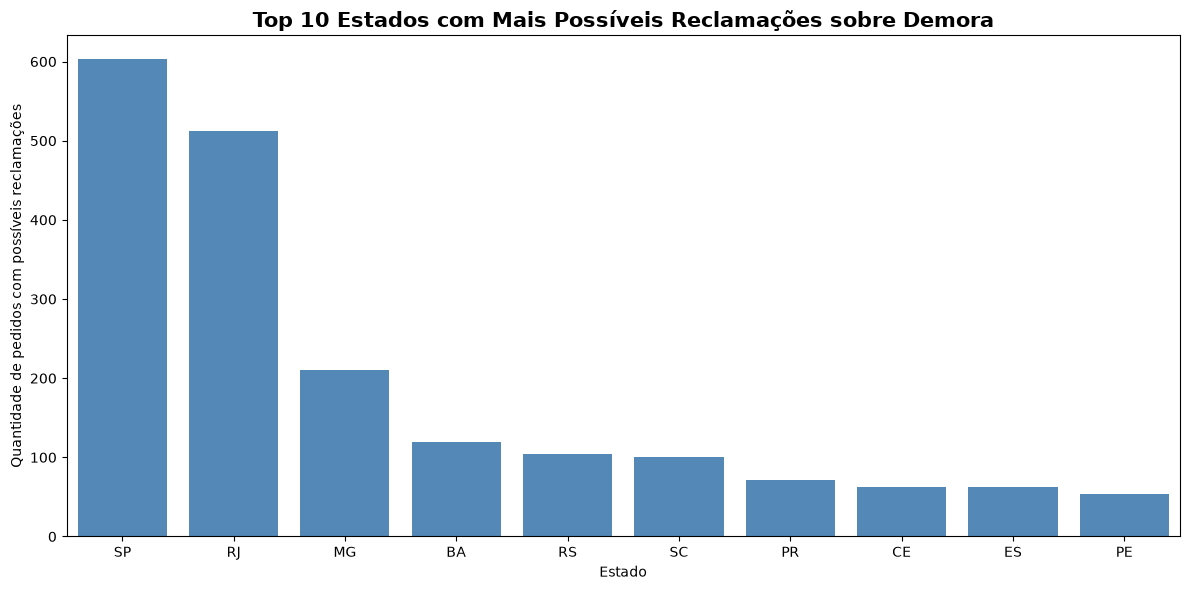

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar os 10 estados com mais possíveis reclamações
top10_estados = ranking_reclamacoes.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_estados,
    x="customer_state",
    y="pedidos_com_reclamacao",
    color="#4389C7"
)

plt.title(
    "Top 10 Estados com Mais Possíveis Reclamações sobre Demora",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Estado")
plt.ylabel("Quantidade de pedidos com possíveis reclamações")

plt.tight_layout()

# Salvar imagem
plt.savefig(
    "../reports/figuras/reclamacoes_por_estado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

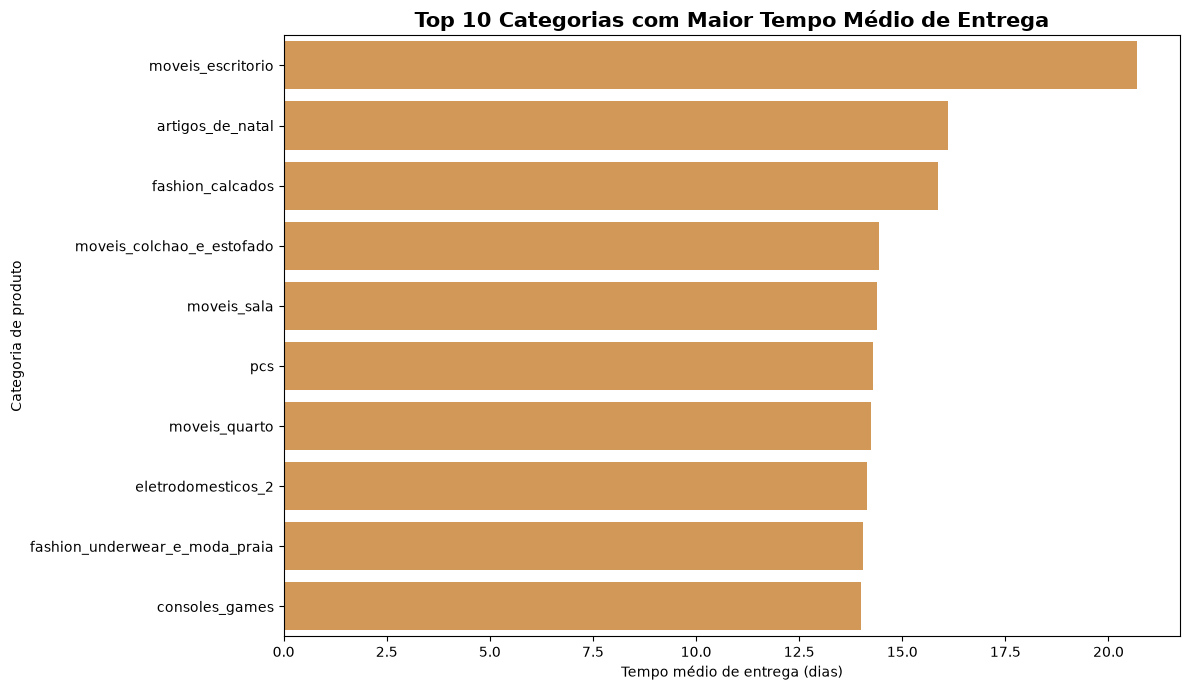

In [8]:
# Selecionar as 10 categorias com maior tempo médio
top10_categorias = ranking_categorias.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10_categorias,
    y="product_category_name_display",
    x="tempo_medio_dias",
    color="#E69A42"
)

plt.title(
    "Top 10 Categorias com Maior Tempo Médio de Entrega",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Tempo médio de entrega (dias)")
plt.ylabel("Categoria de produto")

plt.tight_layout()

# Salvar imagem
plt.savefig(
    "../reports/figuras/tempo_entrega_por_categoria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()